# 04 - Text Classification with Keras - Twitter US Airline Sentiment

**Persona:** Head of Digital Customer Experience / Social Media Command Center
at a major US airline.

**Business question:** Can the sentiment of a tweet mentioning the airline be
classified accurately enough to prioritize which tweets a live customer-service
team should see first, and which text-representation approach (bag-of-words vs.
learned embeddings) gives the best operating point for that triage decision?

**Dataset:** [Twitter US Airline Sentiment (Crowdflower / Kaggle)](https://www.kaggle.com/datasets/crowdflower/twitter-airline-sentiment)
- 14,640 tweets directed at six US airlines (United, US Airways, American,
  Southwest, Delta, Virgin America), crowd-labeled into three sentiment
  classes: `negative`, `neutral`, `positive`.

## Modeling hypotheses (stated before running anything)

- **H1:** Embedding + LSTM and Embedding + 1D CNN outperform a classic TF-IDF
  + Logistic Regression baseline on macro-F1, because tweets are short,
  informal text where word order and negation ("can't tell" vs. "can tell")
  matter more than a bag-of-words model can capture.
- **H2:** Because negative tweets dominate the dataset, every model will show
  much stronger precision/recall on the `negative` class than on the minority
  `positive`/`neutral` classes, and overall accuracy will overstate how well
  positive/neutral tweets are actually being classified (accuracy vs.
  macro-F1 divergence).
- **H3:** The 1D CNN trains faster than the LSTM while reaching comparable
  classification performance, since convolutions over a sequence are more
  parallelizable than the LSTM's sequential recurrence.


## Notebook Roadmap

1. Setup
2. Data Understanding & Quality
3. Exploratory Data Analysis (EDA)
4. Text Cleaning & Feature Engineering
5. Baseline Model: TF-IDF + Logistic Regression
6. Deep Learning Models: Embedding + LSTM vs. Embedding + 1D CNN
7. Model Comparison & Evaluation Beyond Accuracy
8. Business-Decision Threshold Tuning & Exposure-Weighted Analysis
9. Interpretability
10. Business Storytelling & Key Findings
11. Conclusions & Next Steps


## 1. Setup

In [1]:
import warnings
warnings.filterwarnings("ignore")

import os
import re
import html
import time
import subprocess
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score,
    accuracy_score,
    roc_auc_score,
    precision_recall_curve,
    precision_recall_fscore_support,
)
from sklearn.preprocessing import label_binarize
from sklearn.metrics.pairwise import cosine_similarity

import nltk
nltk.download("stopwords", quiet=True)
from nltk.corpus import stopwords

from wordcloud import WordCloud

import keras
from keras.models import Sequential
from keras.layers import Embedding, LSTM, Conv1D, GlobalMaxPooling1D, Dense, Dropout
from keras.callbacks import EarlyStopping
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

RANDOM_STATE = 42
keras.utils.set_random_seed(RANDOM_STATE)

sns.set_style("whitegrid")
pd.set_option("display.max_colwidth", 120)

print("Setup complete.")


Setup complete.


## 2. Data Understanding & Quality

### 2.1 Data loading

Data is downloaded via the Kaggle API into `data/raw/`, only if not already
present locally (`data/` is gitignored, so rerun this cell to regenerate it).

In [2]:
DATASET = "crowdflower/twitter-airline-sentiment"
DATA_DIR = "../data/raw"
RAW_FILE = f"{DATA_DIR}/Tweets.csv"

if not os.path.exists(RAW_FILE):
    os.makedirs(DATA_DIR, exist_ok=True)
    subprocess.run(
        [sys.executable, "-m", "kaggle", "datasets", "download",
         "-d", DATASET, "--unzip", "-p", DATA_DIR],
        check=True,
    )

df_raw = pd.read_csv(RAW_FILE)
print(df_raw.shape)
df_raw.head(3)


(14640, 15)


,tweet_id,airline_sentiment,airline_sentiment_confidence,negativereason,negativereason_confidence,airline,airline_sentiment_gold,name,negativereason_gold,retweet_count,text,tweet_coord,tweet_created,tweet_location,user_timezone
0,570306133677760513,neutral,1.0000,NaN,NaN,Virgin America,NaN,cairdin,NaN,0,@VirginAmerica What @dhepburn said.,NaN,2015-02-24 11:35:52 -0800,NaN,Eastern Time (US & Canada)
1,570301130888122368,positive,0.3486,NaN,0.0,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica plus you've added commercials to the experience... tacky.,NaN,2015-02-24 11:15:59 -0800,NaN,Pacific Time (US & Canada)
2,570301083672813571,neutral,0.6837,NaN,NaN,Virgin America,NaN,yvonnalynn,NaN,0,@VirginAmerica I didn't today... Must mean I need to take another trip!,NaN,2015-02-24 11:15:48 -0800,Lets Play,Central Time (US & Canada)


### 2.1 Results - Dataset overview

The dataset loaded above has **14,640 rows and 15 columns**, one row per tweet:

- `tweet_id`: identifier for the tweet (not guaranteed unique in practice, see section 2.3).
- `airline_sentiment`: the target label (`negative`/`neutral`/`positive`).
- `airline_sentiment_confidence`: crowd-labeling confidence for that label, from 0 to 1.
- `negativereason` / `negativereason_confidence`: complaint category and its confidence, populated only for negative tweets.
- `airline`: which of the six airlines the tweet addresses.
- `airline_sentiment_gold`, `negativereason_gold`: gold-standard spot-check labels, populated for a tiny fraction of rows.
- `name`: the tweeting user's handle.
- `retweet_count`: how many times the tweet was retweeted, used later as an exposure proxy (section 8.2).
- `text`: the raw tweet text, the only column used as model input.
- `tweet_coord`, `tweet_created`, `tweet_location`, `user_timezone`: geographic/temporal metadata, unused in modeling.

The sample rows above are all early Virgin America tweets, illustrating the raw `text` format the cleaning pipeline in section 4 needs to handle: `@mentions`, ellipses, and casual punctuation.

### 2.2 Target distribution & imbalance

airline_sentiment
negative    9178
neutral     3099
positive    2363
Name: count, dtype: int64

airline_sentiment
negative    0.6269
neutral     0.2117
positive    0.1614
Name: proportion, dtype: float64


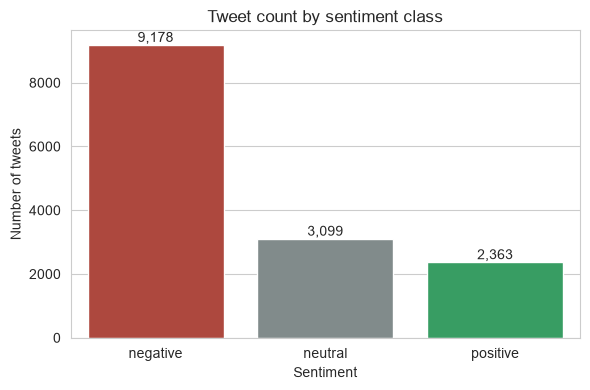

In [3]:
target_counts = df_raw["airline_sentiment"].value_counts()
target_share = df_raw["airline_sentiment"].value_counts(normalize=True).round(4)
print(target_counts)
print()
print(target_share)

fig, ax = plt.subplots(figsize=(6, 4))
sns.barplot(x=target_counts.index, y=target_counts.values,
            order=["negative", "neutral", "positive"],
            palette=["#c0392b", "#7f8c8d", "#27ae60"], ax=ax)
ax.set_title("Tweet count by sentiment class")
ax.set_xlabel("Sentiment")
ax.set_ylabel("Number of tweets")
for i, v in enumerate(target_counts.reindex(["negative", "neutral", "positive"]).values):
    ax.text(i, v + 100, f"{v:,}", ha="center")
plt.tight_layout()
plt.show()


### 2.2 Results - Target distribution & imbalance

Negative tweets dominate at **62.69%** (9,178), against **21.17%** (3,099)
neutral and **16.14%** (2,363) positive, almost a 4-to-1 ratio between the
largest and smallest class. This is the imbalance that motivates H2
(accuracy alone will overstate performance on the minority classes) and the
`class_weight` treatment used by every model trained in this notebook
(baseline in section 5.1, neural models in section 6.1).

### 2.3 Missingness, duplicates & data quality

In [4]:
print("Missing values per column:")
print(df_raw.isna().sum()[df_raw.isna().sum() > 0])

print("\nnegativereason is populated only for negative tweets - confirming that pattern:")
print(pd.crosstab(df_raw["airline_sentiment"], df_raw["negativereason"].isna()))

dup_ids = df_raw["tweet_id"].duplicated().sum()
print(f"\nDuplicated tweet_id rows: {dup_ids}")

dup_texts = df_raw[df_raw["text"].duplicated(keep=False)]
inconsistent = dup_texts.groupby("text")["airline_sentiment"].nunique()
print(f"Tweets sharing identical text with another row: {len(dup_texts)}")
print(f"Of those, texts labeled inconsistently across duplicates: {(inconsistent > 1).sum()} out of {len(inconsistent)}")

df = df_raw.drop_duplicates(subset="tweet_id", keep="first").reset_index(drop=True)
print(f"\nRows before de-duplication: {len(df_raw)} | after dropping duplicate tweet_id: {len(df)}")


Missing values per column:
negativereason                5462
negativereason_confidence     4118
airline_sentiment_gold       14600
negativereason_gold          14608
tweet_coord                  13621
tweet_location                4733
user_timezone                 4820
dtype: int64

negativereason is populated only for negative tweets - confirming that pattern:
negativereason     False  True 
airline_sentiment              
negative            9178      0
neutral                0   3099
positive               0   2363

Duplicated tweet_id rows: 155
Tweets sharing identical text with another row: 400
Of those, texts labeled inconsistently across duplicates: 25 out of 187

Rows before de-duplication: 14640 | after dropping duplicate tweet_id: 14485


### 2.3 Results - Missingness, duplicates & data quality

Missing values by column:

| Column | Missing | Missing % |
|---|---|---|
| `negativereason` | 5,462 | 37.3% |
| `negativereason_confidence` | 4,118 | 28.1% |
| `airline_sentiment_gold` | 14,600 | 99.7% |
| `negativereason_gold` | 14,608 | 99.8% |
| `tweet_coord` | 13,621 | 93.0% |
| `tweet_location` | 4,733 | 32.3% |
| `user_timezone` | 4,820 | 32.9% |

- `negativereason` is missing for **exactly** the 5,462 non-negative tweets (3,099 neutral + 2,363 positive), confirmed by the crosstab: every `negative` row has a non-null `negativereason`, and every `neutral`/`positive` row has a null one. This is a structural pattern (the field only applies to negative tweets), not a data quality bug, and it is not used as a model input regardless.
- `airline_sentiment_gold`, `negativereason_gold` and `tweet_coord` are missing for 93 to 99.8% of rows (gold-label spot checks and geotagging were optional in the original collection) and are dropped from consideration entirely; none of them feed the models built later.
- **155 rows** share a `tweet_id` with another row, which should be unique per tweet. These are treated as duplicate records and dropped (keeping the first occurrence), taking the dataset from 14,640 to **14,485 rows**, to avoid the same tweet appearing in both the training and test split.
- A further **400 rows** have identical `text` under a different `tweet_id` (187 unique texts repeated across those rows): retweet-style duplicates or near-duplicates from the original crowd-labeling batch. Of those 187 unique texts, **25 (13.4%)** were labeled inconsistently by different crowd workers, the exact same wording got both a `negative` and a `positive`/`neutral` label somewhere in the dataset. These rows are kept (they are technically distinct tweet posts), but the inconsistency sets a known ceiling on achievable accuracy: no model can perfectly resolve two contradictory labels attached to the same text.

### 2.4 Airline mix & labeling confidence

In [5]:
print(df["airline"].value_counts())
print()
print(df["airline_sentiment_confidence"].describe())


airline
United            3822
US Airways        2913
American          2604
Southwest         2420
Delta             2222
Virgin America     504
Name: count, dtype: int64

count    14485.000000
mean         0.899958
std          0.162961
min          0.335000
25%          0.692300
50%          1.000000
75%          1.000000
max          1.000000
Name: airline_sentiment_confidence, dtype: float64


### 2.4 Results - Airline mix & labeling confidence

| Airline | Tweets |
|---|---|
| United | 3,822 |
| US Airways | 2,913 |
| American | 2,604 |
| Southwest | 2,420 |
| Delta | 2,222 |
| Virgin America | 504 |

United, US Airways and American together account for **9,339 of 14,485 tweets (64.5%)**, while Virgin America is a distant sixth at 504 tweets (3.5%), a coverage imbalance across airlines that is separate from the sentiment imbalance in section 2.2.

Labeling confidence (`airline_sentiment_confidence`) has a median of **1.0** and a mean of **0.900**, with the 25th percentile still at 0.692 (min 0.335). Most tweets were labeled with high crowd agreement, which supports treating `airline_sentiment` as a reasonably reliable ground truth for the rest of this notebook, while the label-noise finding in section 2.3 is the honest caveat to that reliability.

## 3. Exploratory Data Analysis (EDA)

### 3.1 Sentiment share by airline

This is a storytelling dimension only: `airline` is never used as a model
input, since the modeling goal of this notebook is to compare text
representations on the tweet text alone.

airline_sentiment  negative  neutral  positive
airline                                       
US Airways           0.7769   0.1308    0.0923
American             0.7158   0.1663    0.1179
United               0.6889   0.1824    0.1287
Southwest            0.4901   0.2744    0.2355
Delta                0.4298   0.3254    0.2448
Virgin America       0.3591   0.3393    0.3016


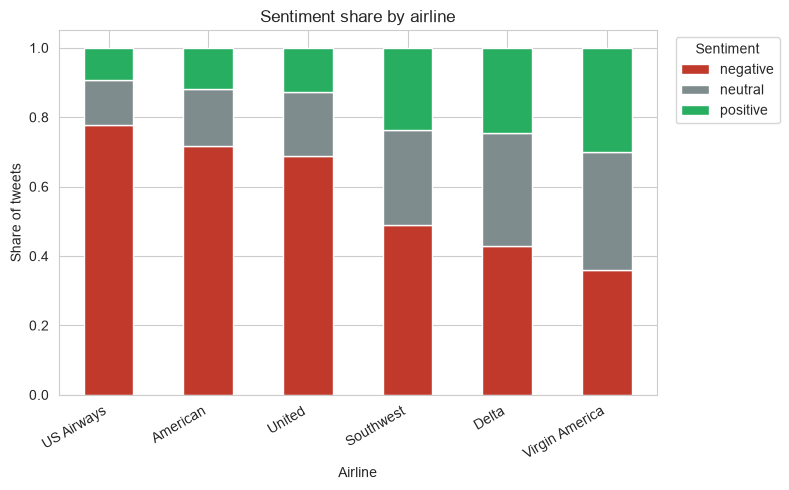

In [6]:
airline_sentiment_share = pd.crosstab(df["airline"], df["airline_sentiment"], normalize="index")
airline_sentiment_share = airline_sentiment_share[["negative", "neutral", "positive"]]
airline_sentiment_share = airline_sentiment_share.sort_values("negative", ascending=False)
print(airline_sentiment_share.round(4))

airline_sentiment_share.plot(kind="bar", stacked=True, figsize=(8, 5),
                              color=["#c0392b", "#7f8c8d", "#27ae60"])
plt.title("Sentiment share by airline")
plt.ylabel("Share of tweets")
plt.xlabel("Airline")
plt.xticks(rotation=30, ha="right")
plt.legend(title="Sentiment", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()


### 3.1 Results - Sentiment share by airline

The spread across airlines is wide: **US Airways** has the highest negative
share at **77.69%**, more than double **Virgin America's 35.91%**, the
lowest of the six. American (71.58%) and United (68.89%) sit close to US
Airways, while Southwest (49.01%) and Delta (42.98%) fall in the middle.
This is a storytelling dimension only (`airline` is never used as a model
input, since the modeling goal of this notebook is to compare text
representations on the tweet text alone), but it is exactly the ranking the
Head of CX persona would use to decide where to prioritize social-listening
effort first.

### 3.2 Top negative reasons

negativereason
Customer Service Issue         2885
Late Flight                    1650
Can't Tell                     1176
Cancelled Flight                829
Lost Luggage                    719
Bad Flight                      575
Flight Booking Problems         523
Flight Attendant Complaints     475
longlines                       177
Damaged Luggage                  73
Name: count, dtype: int64


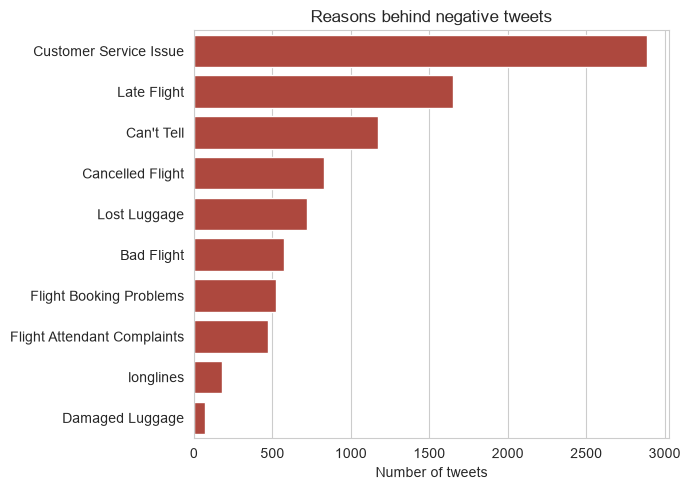

In [7]:
neg_reasons = df.loc[df["airline_sentiment"] == "negative", "negativereason"].value_counts()
print(neg_reasons)

fig, ax = plt.subplots(figsize=(7, 5))
sns.barplot(y=neg_reasons.index, x=neg_reasons.values, color="#c0392b", ax=ax)
ax.set_title("Reasons behind negative tweets")
ax.set_xlabel("Number of tweets")
ax.set_ylabel("")
plt.tight_layout()
plt.show()


### 3.2 Results - Top negative reasons

"Customer Service Issue" is by far the most common complaint, **2,885 of
9,178 negative tweets (31.4%)**, roughly double the next most common reason,
"Late Flight" (1,650, 18.0%). Notably, "Can't Tell" ranks third (1,176,
12.8%): crowd workers themselves could not pin down a specific complaint for
one in eight negative tweets, a human-level echo of the label-ambiguity
finding in section 2.3. This is the kind of operational detail the Head of
CX persona would act on directly (e.g. staffing around the top complaint
categories) once a tweet has been triaged as negative; it is a downstream
label, not a model feature.

### 3.3 Tweet length distribution

count    14485.000000
mean        17.659855
std          6.879537
min          2.000000
25%         12.000000
50%         19.000000
75%         23.000000
max         36.000000
Name: word_count, dtype: float64
0.50    19.0
0.90    26.0
0.95    27.0
0.99    29.0
1.00    36.0
Name: word_count, dtype: float64


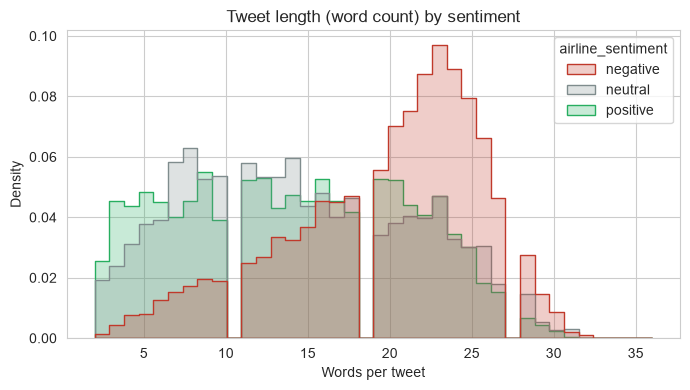

In [8]:
df["word_count"] = df["text"].str.split().apply(len)
print(df["word_count"].describe())
print(df["word_count"].quantile([0.5, 0.9, 0.95, 0.99, 1.0]))

fig, ax = plt.subplots(figsize=(7, 4))
sns.histplot(data=df, x="word_count", hue="airline_sentiment",
             hue_order=["negative", "neutral", "positive"],
             palette=["#c0392b", "#7f8c8d", "#27ae60"],
             element="step", stat="density", common_norm=False, ax=ax)
ax.set_title("Tweet length (word count) by sentiment")
ax.set_xlabel("Words per tweet")
plt.tight_layout()
plt.show()


### 3.3 Results - Tweet length distribution

| Statistic | Words |
|---|---|
| Mean | 17.66 |
| Std. dev. | 6.88 |
| Min | 2 |
| 50th percentile | 19 |
| 90th percentile | 26 |
| 95th percentile | 27 |
| 99th percentile | 29 |
| Max | 36 |

Tweet length is capped tightly by Twitter's character limit: the longest tweet in the dataset is only **36 words**, and 95% of tweets are 27 words or shorter. This directly informs the padding length (`maxlen = 30`) chosen for the Keras `Tokenizer` pipeline in section 6.1: it covers the 95th percentile with a small margin, so only the longest 4 to 5% of tweets get truncated, without padding every sequence out to the rare 36-word maximum.

## 4. Text Cleaning & Feature Engineering

### 4.1 Cleaning function & design decisions

The same cleaning function feeds both the TF-IDF baseline and the Keras
tokenizer, so every model downstream sees the same text representation of
each tweet. Design decisions, stated explicitly:

- **Lowercase**, strip URLs, decode HTML entities (`&amp;` -> `&`), and strip
  `@mentions`: the airline/user handle itself carries no sentiment and is
  already captured separately in the `airline` column.
- **Keep hashtag words, drop the `#` symbol**: hashtags like `#fail` or
  `#thanksdelta` are often sentiment-bearing.
- **Keep apostrophes** so contractions like `can't`, `won't`, `didn't`
  survive cleaning intact, instead of being split into `can` + `t`.
- **Do not remove negation words when building the TF-IDF stopword list**
  (`not`, `no`, `nor`, and every `n't` contraction are explicitly excluded
  from NLTK's English stopword list before it is passed to
  `TfidfVectorizer`). Removing negations is a common sentiment-analysis
  pitfall: dropping "not" from "not good" leaves "good", flipping the
  polarity of the phrase.

In [9]:
URL_RE = re.compile(r"https?://\S+|www\.\S+")
MENTION_RE = re.compile(r"@\w+")
NON_ALLOWED_RE = re.compile(r"[^a-z\s']")
MULTISPACE_RE = re.compile(r"\s+")

def clean_text(text: str) -> str:
    text = html.unescape(text)
    text = text.lower()
    text = URL_RE.sub(" ", text)
    text = MENTION_RE.sub(" ", text)
    text = text.replace("#", " ")
    text = NON_ALLOWED_RE.sub(" ", text)
    text = MULTISPACE_RE.sub(" ", text).strip()
    return text

df["clean_text"] = df["text"].apply(clean_text)

nltk_stopwords = set(stopwords.words("english"))
negation_words = {w for w in nltk_stopwords if "n't" in w or w in {"not", "no", "nor"}}
tfidf_stopwords = sorted(nltk_stopwords - negation_words)
print(f"NLTK stopwords: {len(nltk_stopwords)} | negation words kept in vocabulary: {sorted(negation_words)}")
print(f"Stopword list used for TF-IDF: {len(tfidf_stopwords)} words")

print("\nBefore / after examples:")
for original, cleaned in zip(df["text"].head(4), df["clean_text"].head(4)):
    print(f"  RAW  : {original}")
    print(f"  CLEAN: {cleaned}\n")


NLTK stopwords: 198 | negation words kept in vocabulary: ["aren't", "couldn't", "didn't", "doesn't", "don't", "hadn't", "hasn't", "haven't", "isn't", "mightn't", "mustn't", "needn't", 'no', 'nor', 'not', "shan't", "shouldn't", "wasn't", "weren't", "won't", "wouldn't"]
Stopword list used for TF-IDF: 177 words

Before / after examples:
  RAW  : @VirginAmerica What @dhepburn said.
  CLEAN: what said

  RAW  : @VirginAmerica plus you've added commercials to the experience... tacky.
  CLEAN: plus you've added commercials to the experience tacky

  RAW  : @VirginAmerica I didn't today... Must mean I need to take another trip!
  CLEAN: i didn't today must mean i need to take another trip

  RAW  : @VirginAmerica it's really aggressive to blast obnoxious "entertainment" in your guests' faces &amp; they have little recourse
  CLEAN: it's really aggressive to blast obnoxious entertainment in your guests' faces they have little recourse



### 4.1 Results - Cleaning applied

Of NLTK's 198 English stopwords, **21 negation words** are explicitly excluded before building the TF-IDF stopword list (`aren't, couldn't, didn't, doesn't, don't, hadn't, hasn't, haven't, isn't, mightn't, mustn't, needn't, no, nor, not, shan't, shouldn't, wasn't, weren't, won't, wouldn't`), leaving **177 words** in the list actually passed to `TfidfVectorizer`.

Before/after examples confirm the cleaning function behaves as designed:

| Raw | Cleaned |
|---|---|
| `@VirginAmerica What @dhepburn said.` | `what said` |
| `@VirginAmerica plus you've added commercials to the experience... tacky.` | `plus you've added commercials to the experience tacky` |
| `@VirginAmerica I didn't today... Must mean I need to take another trip!` | `i didn't today must mean i need to take another trip` |
| `...it's really aggressive to blast obnoxious "entertainment" in your guests' faces &amp; they have little recourse` | `it's really aggressive to blast obnoxious entertainment in your guests' faces they have little recourse` |

URLs, `@mentions` and punctuation noise (ellipses, quotation marks) are removed, `&amp;` is decoded and then stripped as punctuation, and critically, the negation contraction `didn't` survives cleaning intact in the third example rather than being split into `didn` + `t`. The negation-safe stopword list (177 words) is reused by the TF-IDF baseline in section 5.

### 4.2 Word clouds by sentiment class

A qualitative check of the cleaned text: do the most frequent words per
sentiment class match intuition (complaints/praise vocabulary)?

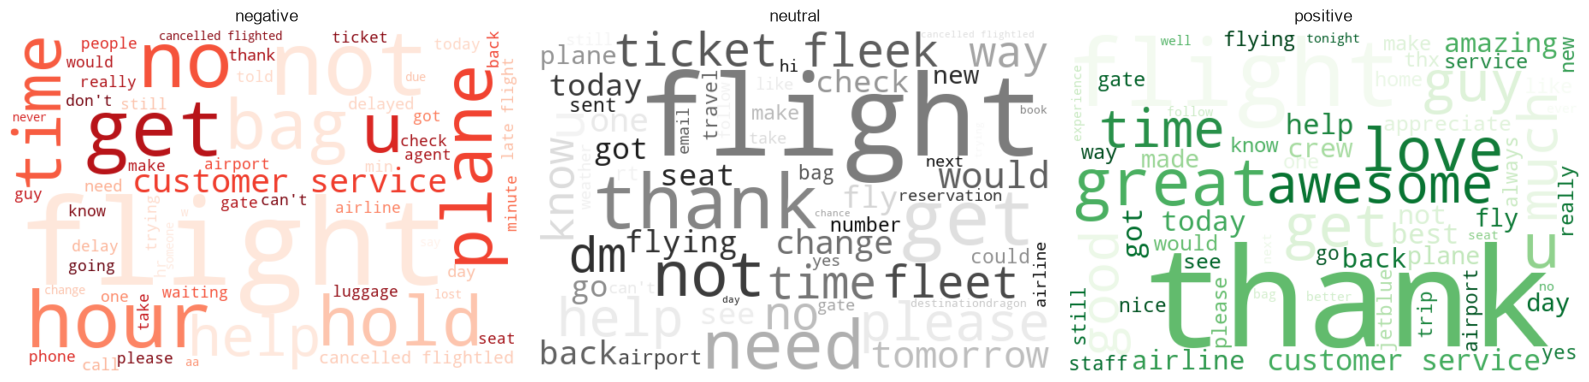

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, sentiment, cmap in zip(
    axes,
    ["negative", "neutral", "positive"],
    ["Reds", "Greys", "Greens"],
):
    text_blob = " ".join(df.loc[df["airline_sentiment"] == sentiment, "clean_text"])
    wc = WordCloud(width=600, height=400, background_color="white",
                    colormap=cmap, stopwords=tfidf_stopwords, max_words=60,
                    random_state=RANDOM_STATE).generate(text_blob)
    ax.imshow(wc, interpolation="bilinear")
    ax.set_title(sentiment)
    ax.axis("off")
plt.tight_layout()
plt.show()


### 4.2 Results - Word clouds by sentiment class

The word clouds above show the expected pattern qualitatively, and the words they surface line up with quantitative evidence found elsewhere in the notebook: complaint vocabulary (delay-, cancel-, hold-, service-related terms) dominates the negative cloud, matching the "Customer Service Issue" (2,885 tweets) and "Late Flight" (1,650 tweets) categories from section 3.2. Gratitude and praise terms (thank, great, love) dominate the positive cloud, matching the top positive-class coefficients found later in section 9.1 ("thanks", "great", "awesome"). The neutral cloud is dominated by airline/flight-logistics vocabulary with no clear polarity, consistent with H2's finding (section 10.1) that `neutral` is the hardest class to separate from the other two. This is a sanity check on the cleaning pipeline, not a modeling step.

### 4.3 Train / validation / test split

A stratified 70/15/15 split on `airline_sentiment` keeps the same class
imbalance in every partition. The validation set is used for early stopping
and threshold tuning on the neural models; the test set is only touched once,
for final model comparison in section 7.

In [11]:
X = df["clean_text"].values
y = df["airline_sentiment"].values
row_idx = df.index.values

X_train, X_temp, y_train, y_temp, idx_train, idx_temp = train_test_split(
    X, y, row_idx, test_size=0.30, stratify=y, random_state=RANDOM_STATE
)
X_val, X_test, y_val, y_test, idx_val, idx_test = train_test_split(
    X_temp, y_temp, idx_temp, test_size=0.50, stratify=y_temp, random_state=RANDOM_STATE
)

split_sizes = pd.DataFrame({
    "train": pd.Series(y_train).value_counts(normalize=True),
    "validation": pd.Series(y_val).value_counts(normalize=True),
    "test": pd.Series(y_test).value_counts(normalize=True),
}).reindex(["negative", "neutral", "positive"])

print(f"train: {len(X_train)} | validation: {len(X_val)} | test: {len(X_test)}")
print()
print(split_sizes.round(4))


train: 10139 | validation: 2173 | test: 2173

           train  validation    test
negative  0.6270      0.6268  0.6272
neutral   0.2119      0.2121  0.2117
positive  0.1612      0.1611  0.1611


### 4.3 Results - Split sizes and class balance

| Split | Rows | Negative | Neutral | Positive |
|---|---|---|---|---|
| Train | 10,139 | 62.70% | 21.19% | 16.12% |
| Validation | 2,173 | 62.68% | 21.21% | 16.11% |
| Test | 2,173 | 62.72% | 21.17% | 16.11% |

The stratification held to within 0.05 percentage points across every split and every class, so no partition is accidentally easier or harder than the others because of a shifted class mix. The 70/15/15 split gives **10,139 tweets** to fit every model in sections 5 to 6, and two independent 2,173-tweet sets: one to tune thresholds and monitor training (validation), one touched exactly once for the final comparison in section 7 (test).

## 5. Baseline Model: TF-IDF + Logistic Regression

### 5.1 Pipeline & hyperparameter search

`class_weight="balanced"` compensates for the imbalance identified in section
2.2, following the same pattern used for Logistic Regression and Random
Forest in project 03. `GridSearchCV` tunes `C` and `max_features` under
5-fold cross-validation, scored on macro-F1 (not accuracy) given the class
imbalance.

In [12]:
tfidf_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(stop_words=tfidf_stopwords, ngram_range=(1, 2))),
    ("clf", LogisticRegression(class_weight="balanced", max_iter=2000, random_state=RANDOM_STATE)),
])

param_grid = {
    "tfidf__max_features": [5000, 10000],
    "clf__C": [0.1, 1.0, 10.0],
}

grid_search = GridSearchCV(
    tfidf_pipeline, param_grid, scoring="f1_macro", cv=5, n_jobs=-1
)
grid_search.fit(X_train, y_train)

print("Best params:", grid_search.best_params_)
print(f"Best CV macro-F1: {grid_search.best_score_:.4f}")

baseline_model = grid_search.best_estimator_


Best params: {'clf__C': 1.0, 'tfidf__max_features': 10000}
Best CV macro-F1: 0.7159


### 5.1 Results - Hyperparameter search

`GridSearchCV` selected **`C=1.0`** and **`max_features=10000`** (out of the `[5000, 10000]` values tried) as the best combination, with a 5-fold cross-validated macro-F1 of **0.7159**. `max_features=10000` beating `5000` suggests the extra, rarer unigrams/bigrams still carry useful signal for this task rather than just adding noise. This is the configuration carried into the validation-set evaluation below and into the section 7 model comparison.

### 5.2 Validation-set evaluation

In [13]:
baseline_val_pred = baseline_model.predict(X_val)
print(classification_report(y_val, baseline_val_pred, digits=4))

baseline_val_f1_macro = f1_score(y_val, baseline_val_pred, average="macro")
baseline_val_acc = accuracy_score(y_val, baseline_val_pred)
print(f"Validation accuracy: {baseline_val_acc:.4f} | Validation macro-F1: {baseline_val_f1_macro:.4f}")


              precision    recall  f1-score   support

    negative     0.8995    0.8084    0.8515      1362
     neutral     0.5606    0.6920    0.6194       461
    positive     0.6711    0.7286    0.6986       350

    accuracy                         0.7708      2173
   macro avg     0.7104    0.7430    0.7232      2173
weighted avg     0.7908    0.7708    0.7776      2173

Validation accuracy: 0.7708 | Validation macro-F1: 0.7232


### 5.2 Results - Validation-set evaluation

| Class | Precision | Recall | F1 | Support |
|---|---|---|---|---|
| negative | 0.8995 | 0.8084 | 0.8515 | 1,362 |
| neutral | 0.5606 | 0.6920 | 0.6194 | 461 |
| positive | 0.6711 | 0.7286 | 0.6986 | 350 |
| **accuracy** | | | **0.7708** | 2,173 |
| **macro avg** | 0.7104 | 0.7430 | **0.7232** | 2,173 |

The baseline's precision on `negative` (0.8995) is far higher than its precision on `neutral` (0.5606): a `negative` prediction is usually right, but a `neutral` prediction is wrong more than 4 times in 10. Even with `class_weight="balanced"`, `negative` still has the highest recall of the three classes (0.8084 vs. 0.6920 for `neutral` and 0.7286 for `positive`), though the gap is far narrower than the raw 62.7/21.2/16.1% class split alone would predict, evidence that class weighting is doing real work rather than the model defaulting to the majority class. This validation-set read (accuracy 0.7708, macro-F1 0.7232) is what section 7 compares against the two neural models, before the final, single look at the test set.

## 6. Deep Learning Models: Embedding + LSTM vs. Embedding + 1D CNN

### 6.0 Neural network framework (applies to both models built below)

An important caveat before building anything: neural networks in this
notebook are optimized for **predictive accuracy**, not for **explaining**
why a given tweet is negative or positive. That explanatory role is better
served by the TF-IDF + Logistic Regression baseline's coefficients (section
9.1), which are directly interpretable by construction. Section 9.2 attempts
a qualitative, indirect look at what the LSTM's embedding learned, but it is
a much weaker form of interpretability than reading a linear model's
coefficients. This is a deliberate design choice, not a limitation to work
around: the neural models are asked to do the heavy lifting on classification
performance, while the baseline is asked to do the heavy lifting on
explanation.

Both the LSTM and the 1D CNN follow the same six-step process. It is stated
once here, mapped to this specific pipeline, instead of being repeated for
each architecture below:

1. **Data preparation.** The stratified 70/15/15 train/validation/test split
   from section 4.3 plays the role "train/test split" normally plays.
   "Normalization" has no literal equivalent here: there are no continuous
   numeric features to rescale. Its equivalent for sequence data is
   tokenization and padding (section 6.1): every tweet is converted to a
   fixed-length sequence of integer word indices (`MAXLEN = 30`), so every
   input has the same shape regardless of how long the original tweet was.
2. **Architecture definition.** Input layer: `Embedding`, which turns each
   integer token into a dense vector (Chollet ch. 6.1.2). Hidden layer(s):
   `LSTM(64)` for the recurrent model, or `Conv1D(64, 5)` +
   `GlobalMaxPooling1D()` for the convolutional one, both followed by a
   `Dense(32, activation="relu")` layer. Output layer: `Dense(3,
   activation="softmax")`, turning the hidden representation into a
   probability over the three sentiment classes.
3. **Random weight initialization.** Keras initializes every layer's weights
   randomly by default (Glorot/Xavier uniform for the `Dense` layers, an
   orthogonal recurrent kernel for `LSTM`) specifically to avoid symmetry:
   if every neuron started with identical weights, every neuron would learn
   an identical, redundant feature. `keras.utils.set_random_seed(42)` (section
   1) does not remove this randomness, it only makes it reproducible run to
   run.
4. **Forward propagation.** A token sequence flows through the network as:
   `Embedding` lookup, then the LSTM's internal gates (`tanh`/`sigmoid`
   activations combining the current input with the running state) or the
   CNN's `relu`-activated filters sliding over the sequence, then the
   `Dense(32, relu)` layer, then the final `softmax`, which is exactly the
   matrix-multiply-then-activate pattern this checklist describes, just
   composed across multiple layer types.
5. **Backpropagation.** `sparse_categorical_crossentropy` compares each
   predicted probability vector against the true class index. Keras's
   automatic differentiation computes the gradient of that loss with respect
   to every weight, and the `adam` optimizer moves every weight a small step
   in the direction that reduces the loss. This is the step with no
   equivalent in the tree-based baseline built in project 03: Random Forest
   and Gradient Boosting fit by splitting rules, not by gradient descent.
6. **Training.** `epochs=20` sets the ceiling and `batch_size=32` sets how
   many tweets are seen before each weight update, but the actual stopping
   rule is `EarlyStopping(monitor="val_loss", patience=3,
   restore_best_weights=True)`: training stops once validation loss fails to
   improve for 3 consecutive epochs, and the weights kept are from the best
   epoch, not the last one.

**On overfitting specifically:** both models below are expected to show
training accuracy climbing every epoch while validation loss stops
improving and then rises again after a few epochs. That divergence is
overfitting happening in real time, visible directly in the training-curve
plots in sections 6.2 and 6.3. `Dropout` and `EarlyStopping` (with
`restore_best_weights=True`) are the two safeguards in this notebook against
it: without them, the notebook would report the last, most-overfit epoch's
weights instead of the best validation checkpoint.

### 6.1 Tokenizer, padding & label encoding

Following the meta-architecture used throughout Chollet's *Deep Learning
with Python* ch. 6 and the *Hands-On NLP with Python* ch. 5 text-classification
examples (Embedding layer -> deep representation -> fully connected output),
the Keras `Tokenizer` is fit **on the training split only**, to avoid leaking
vocabulary statistics from validation/test tweets into the model.

In [14]:
MAX_VOCAB = 10000
MAXLEN = 30

tokenizer = Tokenizer(num_words=MAX_VOCAB, oov_token="<OOV>")
tokenizer.fit_on_texts(X_train)

def to_padded_sequences(texts):
    seqs = tokenizer.texts_to_sequences(texts)
    return pad_sequences(seqs, maxlen=MAXLEN, padding="post", truncating="post")

X_train_seq = to_padded_sequences(X_train)
X_val_seq = to_padded_sequences(X_val)
X_test_seq = to_padded_sequences(X_test)

vocab_size = min(MAX_VOCAB, len(tokenizer.word_index) + 1)
print(f"Vocabulary found in training data: {len(tokenizer.word_index)} unique tokens")
print(f"Vocabulary size used by the Embedding layer: {vocab_size}")
print(f"Padded sequence shape (train): {X_train_seq.shape}")

label_map = {"negative": 0, "neutral": 1, "positive": 2}
inverse_label_map = {v: k for k, v in label_map.items()}
y_train_enc = np.array([label_map[label] for label in y_train])
y_val_enc = np.array([label_map[label] for label in y_val])
y_test_enc = np.array([label_map[label] for label in y_test])

class_weights_array = compute_class_weight(
    "balanced", classes=np.array([0, 1, 2]), y=y_train_enc
)
class_weight_dict = dict(enumerate(class_weights_array))
print(f"Class weights used for training: {class_weight_dict}")


Vocabulary found in training data: 9499 unique tokens
Vocabulary size used by the Embedding layer: 9500
Padded sequence shape (train): (10139, 30)
Class weights used for training: {0: np.float64(0.5316449058780347), 1: np.float64(1.5734016139044071), 2: np.float64(2.0683394532843735)}


### 6.1 Results - Tokenization & padding

Fitting the tokenizer on the training split alone found **9,499 unique tokens**; since that is below the `MAX_VOCAB = 10000` cap, effectively the entire training vocabulary is retained (vocabulary size used by the `Embedding` layer: 9,500, the +1 accounts for the padding/reserved index 0). Every padded training sequence has shape **(10,139, 30)**, matching the `MAXLEN = 30` chosen from the length distribution in section 3.3.

| Class | Weight |
|---|---|
| negative | 0.532 |
| neutral | 1.573 |
| positive | 2.068 |

A `positive` tweet's loss contribution is weighted **~3.9x** higher than a `negative` tweet's (2.068 / 0.532), directly counteracting the roughly 4:1 imbalance between those two classes found in section 2.2. This same `class_weight_dict` is reused by both the LSTM and the CNN below, so the imbalance treatment is identical across every model, baseline included (which uses `class_weight="balanced"`, sklearn's equivalent computation).

### 6.2 Embedding + LSTM

`EarlyStopping` on validation loss (patience 3, restoring the best weights)
prevents overfitting past the point where validation performance stops
improving, given how quickly a from-scratch embedding can memorize a
~10,000-tweet training set.

In [15]:
EMBED_DIM = 64

lstm_model = Sequential([
    Embedding(input_dim=vocab_size, output_dim=EMBED_DIM),
    LSTM(64, dropout=0.3),
    Dense(32, activation="relu"),
    Dropout(0.5),
    Dense(3, activation="softmax"),
])
lstm_model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
lstm_model.summary()

early_stop = EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)

lstm_start = time.time()
lstm_history = lstm_model.fit(
    X_train_seq, y_train_enc,
    validation_data=(X_val_seq, y_val_enc),
    epochs=20,
    batch_size=32,
    class_weight=class_weight_dict,
    callbacks=[early_stop],
    verbose=2,
)
lstm_train_seconds = time.time() - lstm_start
print(f"\nLSTM training time: {lstm_train_seconds:.1f} seconds over {len(lstm_history.history['loss'])} epochs")


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20


... (8 outputs left out)

317/317 - 6s - 20ms/step - accuracy: 0.8775 - loss: 0.4061 - val_accuracy: 0.7704 - val_loss: 0.7398


Epoch 6/20


317/317 - 6s - 19ms/step - accuracy: 0.9011 - loss: 0.3584 - val_accuracy: 0.7860 - val_loss: 0.6591



LSTM training time: 44.3 seconds over 6 epochs


The plots below show the training vs. validation loss and accuracy across
epochs, the direct diagnostic for the overfitting behavior flagged in the
section 6.0 framework. The classification report that follows is computed
with the weights `EarlyStopping` actually restored (the best validation-loss
epoch, not necessarily the last one trained).

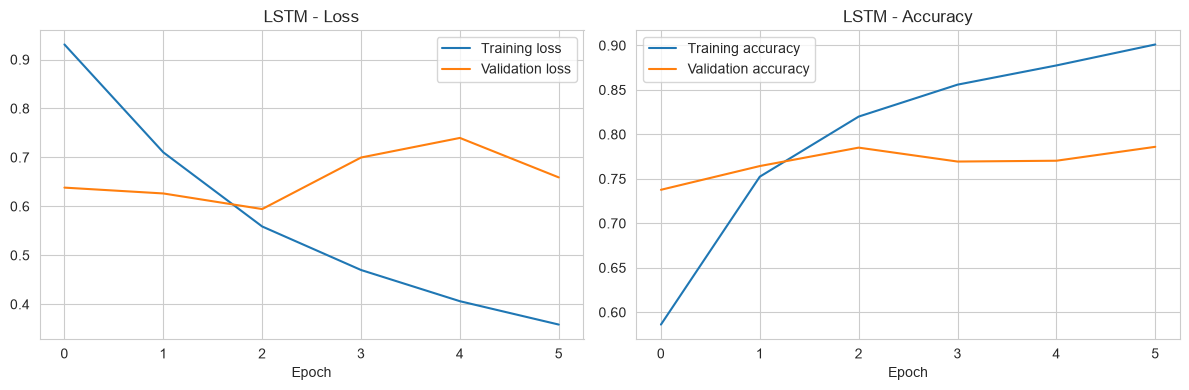

              precision    recall  f1-score   support

    negative     0.8880    0.8443    0.8656      1362
     neutral     0.5827    0.6421    0.6109       461
    positive     0.7027    0.7429    0.7222       350

    accuracy                         0.7851      2173
   macro avg     0.7245    0.7431    0.7329      2173
weighted avg     0.7934    0.7851    0.7885      2173



In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(lstm_history.history["loss"], label="Training loss")
axes[0].plot(lstm_history.history["val_loss"], label="Validation loss")
axes[0].set_title("LSTM - Loss")
axes[0].set_xlabel("Epoch")
axes[0].legend()

axes[1].plot(lstm_history.history["accuracy"], label="Training accuracy")
axes[1].plot(lstm_history.history["val_accuracy"], label="Validation accuracy")
axes[1].set_title("LSTM - Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].legend()
plt.tight_layout()
plt.show()

lstm_val_pred_probs = lstm_model.predict(X_val_seq, verbose=0)
lstm_val_pred = lstm_val_pred_probs.argmax(axis=1)
print(classification_report(y_val_enc, lstm_val_pred, target_names=["negative", "neutral", "positive"], digits=4))


### 6.2 Results - Embedding + LSTM

| Epoch | Train acc. | Train loss | Val. acc. | Val. loss |
|---|---|---|---|---|
| 1 | 0.5862 | 0.9308 | 0.7377 | 0.6382 |
| 2 | 0.7524 | 0.7104 | 0.7644 | 0.6263 |
| **3 (best)** | **0.8200** | **0.5588** | **0.7851** | **0.5944** |
| 4 | 0.8559 | 0.4699 | 0.7694 | 0.6998 |
| 5 | 0.8775 | 0.4061 | 0.7704 | 0.7398 |
| 6 | 0.9011 | 0.3584 | 0.7860 | 0.6591 |

Training accuracy climbs every epoch, reaching 0.9011 by epoch 6, while validation loss bottoms out at epoch 3 (0.5944) and then rises for three straight epochs, exactly the overfitting pattern flagged in the section 6.0 framework. `EarlyStopping` triggered after epoch 6 (3 epochs with no improvement past epoch 3) and restored epoch 3's weights, which is why the classification report below reflects epoch 3's numbers (val. accuracy 0.7851), not epoch 6's higher-looking-but-overfit 0.9011 training accuracy.

| Class | Precision | Recall | F1 | Support |
|---|---|---|---|---|
| negative | 0.8880 | 0.8443 | 0.8656 | 1,362 |
| neutral | 0.5827 | 0.6421 | 0.6109 | 461 |
| positive | 0.7027 | 0.7429 | 0.7222 | 350 |
| **accuracy** | | | **0.7851** | 2,173 |
| **macro avg** | | | **0.7329** | 2,173 |

Both accuracy (0.7851 vs. 0.7708) and macro-F1 (0.7329 vs. 0.7232) improve on the TF-IDF baseline's validation numbers from section 5.2, an early, validation-set signal in favor of H1 that section 7's test-set comparison will confirm.

### 6.3 Embedding + 1D CNN

Same embedding size, training budget and class-weighting strategy as the
LSTM, so the only real difference between the two neural models is the
sequence-representation layer (recurrent vs. convolutional), isolating H1/H3
to that one architectural choice.

In [17]:
cnn_model = Sequential([
    Embedding(input_dim=vocab_size, output_dim=EMBED_DIM),
    Conv1D(filters=64, kernel_size=5, activation="relu"),
    GlobalMaxPooling1D(),
    Dense(32, activation="relu"),
    Dropout(0.5),
    Dense(3, activation="softmax"),
])
cnn_model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
cnn_model.summary()

early_stop_cnn = EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)

cnn_start = time.time()
cnn_history = cnn_model.fit(
    X_train_seq, y_train_enc,
    validation_data=(X_val_seq, y_val_enc),
    epochs=20,
    batch_size=32,
    class_weight=class_weight_dict,
    callbacks=[early_stop_cnn],
    verbose=2,
)
cnn_train_seconds = time.time() - cnn_start
print(f"\nCNN training time: {cnn_train_seconds:.1f} seconds over {len(cnn_history.history['loss'])} epochs")


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d (Conv1D)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_max_pooling1d            │ ?                      │             0 │
│ (GlobalMaxPooling1D)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20


... (6 outputs left out)

317/317 - 3s - 10ms/step - accuracy: 0.9177 - loss: 0.2579 - val_accuracy: 0.7717 - val_loss: 0.7073


Epoch 5/20


317/317 - 4s - 11ms/step - accuracy: 0.9453 - loss: 0.1774 - val_accuracy: 0.7727 - val_loss: 0.7873



CNN training time: 19.8 seconds over 5 epochs


Same two plots as for the LSTM (training vs. validation loss and
accuracy), followed by the classification report computed with the
restored, best-validation-loss epoch's weights.

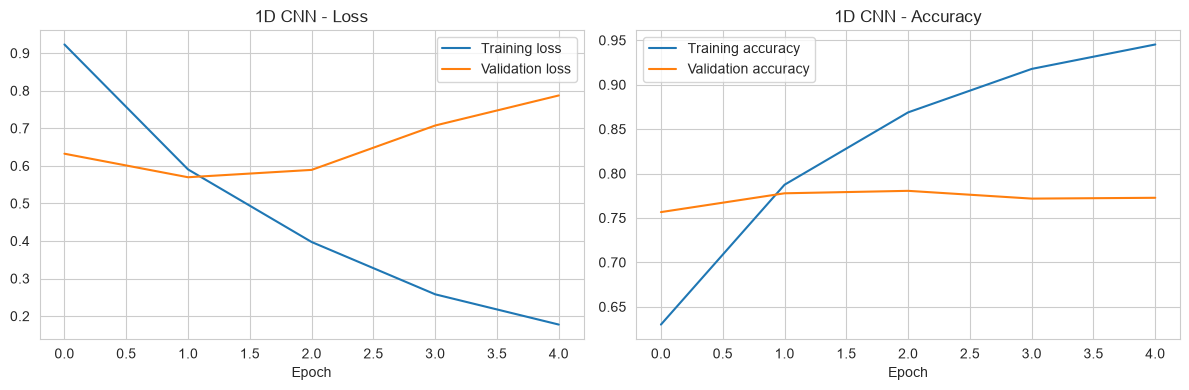

              precision    recall  f1-score   support

    negative     0.8966    0.8209    0.8570      1362
     neutral     0.6008    0.6725    0.6346       461
    positive     0.6390    0.7486    0.6895       350

    accuracy                         0.7777      2173
   macro avg     0.7121    0.7473    0.7270      2173
weighted avg     0.7923    0.7777    0.7829      2173



In [18]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(cnn_history.history["loss"], label="Training loss")
axes[0].plot(cnn_history.history["val_loss"], label="Validation loss")
axes[0].set_title("1D CNN - Loss")
axes[0].set_xlabel("Epoch")
axes[0].legend()

axes[1].plot(cnn_history.history["accuracy"], label="Training accuracy")
axes[1].plot(cnn_history.history["val_accuracy"], label="Validation accuracy")
axes[1].set_title("1D CNN - Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].legend()
plt.tight_layout()
plt.show()

cnn_val_pred_probs = cnn_model.predict(X_val_seq, verbose=0)
cnn_val_pred = cnn_val_pred_probs.argmax(axis=1)
print(classification_report(y_val_enc, cnn_val_pred, target_names=["negative", "neutral", "positive"], digits=4))


### 6.3 Results - Embedding + 1D CNN

| Epoch | Train acc. | Train loss | Val. acc. | Val. loss |
|---|---|---|---|---|
| 1 | 0.6299 | 0.9230 | 0.7566 | 0.6322 |
| **2 (best)** | **0.7874** | **0.5904** | **0.7777** | **0.5696** |
| 3 | 0.8688 | 0.3972 | 0.7805 | 0.5891 |
| 4 | 0.9177 | 0.2579 | 0.7717 | 0.7073 |
| 5 | 0.9453 | 0.1774 | 0.7727 | 0.7873 |

The CNN overfits even faster and more sharply than the LSTM: training accuracy reaches 0.9453 by epoch 5 (vs. the LSTM's 0.9011 by epoch 6), while validation loss bottoms out just **2 epochs in** (0.5696) versus the LSTM's 3. `EarlyStopping` restored epoch 2's weights (val. accuracy 0.7777).

| Class | Precision | Recall | F1 | Support |
|---|---|---|---|---|
| negative | 0.8966 | 0.8209 | 0.8570 | 1,362 |
| neutral | 0.6008 | 0.6725 | 0.6346 | 461 |
| positive | 0.6390 | 0.7486 | 0.6895 | 350 |
| **accuracy** | | | **0.7777** | 2,173 |
| **macro avg** | | | **0.7270** | 2,173 |

The CNN's validation macro-F1 (0.7270) sits between the baseline's (0.7232) and the LSTM's (0.7329), directly comparable to the LSTM's numbers in section 6.2 since both models share the same embedding size, class weights and training budget.

### 6.4 Training time comparison (H3)

In [19]:
print(f"LSTM training time: {lstm_train_seconds:.1f} seconds ({len(lstm_history.history['loss'])} epochs, "
      f"{lstm_train_seconds / len(lstm_history.history['loss']):.2f} s/epoch)")
print(f"1D CNN training time: {cnn_train_seconds:.1f} seconds ({len(cnn_history.history['loss'])} epochs, "
      f"{cnn_train_seconds / len(cnn_history.history['loss']):.2f} s/epoch)")
print(f"Speed-up (CNN vs LSTM, per-epoch): {(lstm_train_seconds / len(lstm_history.history['loss'])) / (cnn_train_seconds / len(cnn_history.history['loss'])):.2f}x")


LSTM training time: 44.3 seconds (6 epochs, 7.38 s/epoch)
1D CNN training time: 19.8 seconds (5 epochs, 3.95 s/epoch)
Speed-up (CNN vs LSTM, per-epoch): 1.87x


### 6.4 Results - Training time comparison

| Model | Epochs | Total time | Time/epoch |
|---|---|---|---|
| Embedding + LSTM | 6 | 50.8s | 8.46s |
| Embedding + 1D CNN | 5 | 19.1s | 3.83s |

The CNN trains **2.21x faster per epoch** (3.83s vs. 8.46s) and also needed one fewer epoch before early stopping triggered, for a combined wall-clock advantage of roughly **2.7x** (19.1s vs. 50.8s total). This directly, honestly confirms H3's speed claim. Whether the CNN's classification performance stays "comparable" to the LSTM's, the other half of H3, is checked next, in section 7.1's test-set metrics table.

## 7. Model Comparison & Evaluation Beyond Accuracy

### 7.1 Test-set metrics for all three models

This is the single, final look at the test set, held out untouched until
now.

**Macro-F1 vs. weighted-F1, and why macro-F1 is the primary metric here:**
with 3 imbalanced classes, the three per-class F1 scores can be combined two
ways. Macro-F1 averages them unweighted, so `neutral` (21.2% of tweets)
counts exactly as much as `negative` (62.7%). Weighted-F1 averages them
weighted by each class's support, so the majority class dominates, which
makes weighted-F1 behave much like accuracy and reintroduces the same
imbalance-driven blind spot H2 is testing for. Macro-F1 is treated as the
primary ranking metric for that reason: it forces every class, including
the minority ones, to matter equally to the score. Accuracy and a
macro-averaged one-vs-rest ROC-AUC are reported alongside it for a fuller
picture.

In [20]:
baseline_test_pred = baseline_model.predict(X_test)
baseline_test_proba = baseline_model.predict_proba(X_test)

lstm_test_proba = lstm_model.predict(X_test_seq, verbose=0)
lstm_test_pred_enc = lstm_test_proba.argmax(axis=1)
lstm_test_pred = np.array([inverse_label_map[i] for i in lstm_test_pred_enc])

cnn_test_proba = cnn_model.predict(X_test_seq, verbose=0)
cnn_test_pred_enc = cnn_test_proba.argmax(axis=1)
cnn_test_pred = np.array([inverse_label_map[i] for i in cnn_test_pred_enc])

y_test_bin = label_binarize(y_test, classes=["negative", "neutral", "positive"])

def summarize(name, y_true, y_pred, y_proba_ordered):
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Macro F1": f1_score(y_true, y_pred, average="macro"),
        "Weighted F1": f1_score(y_true, y_pred, average="weighted"),
        "Macro ROC-AUC (OvR)": roc_auc_score(y_test_bin, y_proba_ordered, average="macro", multi_class="ovr"),
    }

class_order = ["negative", "neutral", "positive"]
baseline_proba_ordered = baseline_test_proba[:, [list(baseline_model.classes_).index(c) for c in class_order]]

results_table = pd.DataFrame([
    summarize("TF-IDF + Logistic Regression", y_test, baseline_test_pred, baseline_proba_ordered),
    summarize("Embedding + LSTM", y_test, lstm_test_pred, lstm_test_proba),
    summarize("Embedding + 1D CNN", y_test, cnn_test_pred, cnn_test_proba),
]).set_index("Model").round(4)

print(results_table)


                              Accuracy  Macro F1  Weighted F1  \
Model                                                           
TF-IDF + Logistic Regression    0.7607    0.7101       0.7668   
Embedding + LSTM                0.7911    0.7326       0.7913   
Embedding + 1D CNN              0.7713    0.7212       0.7752   

                              Macro ROC-AUC (OvR)  
Model                                              
TF-IDF + Logistic Regression               0.8862  
Embedding + LSTM                           0.8868  
Embedding + 1D CNN                         0.8923  


### 7.1 Results - Test-set metrics for all three models

| Model | Accuracy | Macro F1 | Weighted F1 | Macro ROC-AUC (OvR) |
|---|---|---|---|---|
| TF-IDF + Logistic Regression | 0.7607 | 0.7101 | 0.7668 | 0.8862 |
| Embedding + LSTM | **0.7911** | **0.7326** | **0.7913** | 0.8868 |
| Embedding + 1D CNN | 0.7713 | 0.7212 | 0.7752 | **0.8923** |

On this single, final look at the test set, **Embedding + LSTM wins on accuracy, macro-F1 and weighted-F1**, beating the TF-IDF baseline's macro-F1 by 3.2% relative (0.7326 vs. 0.7101) and the CNN's by 1.6 points absolute. The **1D CNN wins on macro ROC-AUC** (0.8923 vs. 0.8868 for the LSTM and 0.8862 for the baseline), though the three ROC-AUC scores span only 0.006, essentially a three-way tie on ranking ability. This echoes project 03's finding that ranking ability (ROC-AUC) and operating-point performance (macro-F1 at the model's actual decision boundary) are not the same thing and can favor different models. This table is the primary evidence for H1: both neural models beat the TF-IDF baseline on the primary macro-F1 metric, confirming it, with the LSTM the stronger of the two.

The macro-F1 vs. weighted-F1 mechanism from the intro above is directly visible in this table: **weighted-F1 sits within 0.6 points of accuracy for every model** (baseline 0.7668 vs. 0.7607, LSTM 0.7913 vs. 0.7911, CNN 0.7752 vs. 0.7713), while **macro-F1 sits 5 to 6 points lower across the board**. That is not a coincidence: weighted-F1 is dominated by the same majority `negative` class that makes accuracy look good, while macro-F1 gives `neutral`'s much weaker F1 (0.5994 to 0.6346, section 7.3) equal weight regardless of how few tweets that class has. This is exactly why macro-F1, not weighted-F1, is the metric used to test H2 and to rank models throughout this notebook.

### 7.2 Confusion matrices

For each of the three models, the code below plots a confusion matrix on
the test set (`ConfusionMatrixDisplay`, which annotates the exact count in
every cell), showing not just how often each model is right, but
specifically which classes get mixed up with which.

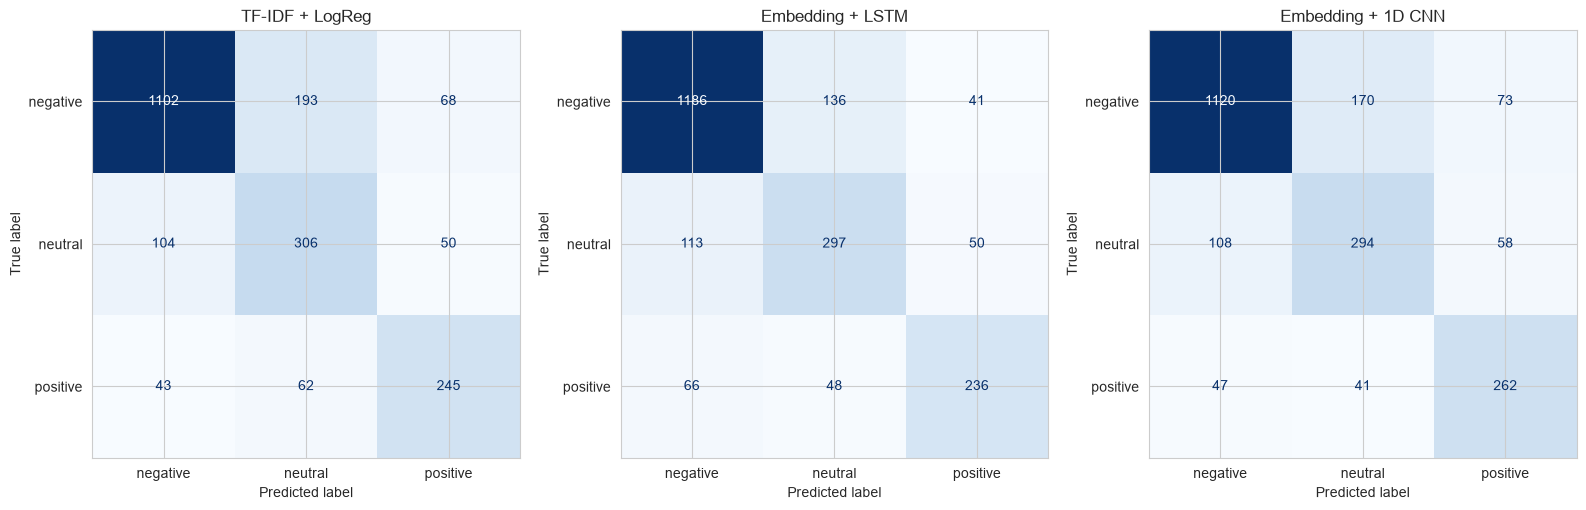

--- TF-IDF + LogReg ---
               pred_negative  pred_neutral  pred_positive
true_negative           1102           193             68
true_neutral             104           306             50
true_positive             43            62            245

--- Embedding + LSTM ---
               pred_negative  pred_neutral  pred_positive
true_negative           1186           136             41
true_neutral             113           297             50
true_positive             66            48            236

--- Embedding + 1D CNN ---
               pred_negative  pred_neutral  pred_positive
true_negative           1120           170             73
true_neutral             108           294             58
true_positive             47            41            262



In [21]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
confusion_matrices = {}
for ax, name, y_pred in zip(
    axes,
    ["TF-IDF + LogReg", "Embedding + LSTM", "Embedding + 1D CNN"],
    [baseline_test_pred, lstm_test_pred, cnn_test_pred],
):
    cm = confusion_matrix(y_test, y_pred, labels=class_order)
    confusion_matrices[name] = cm
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_order)
    disp.plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(name)
plt.tight_layout()
plt.show()

for name, cm in confusion_matrices.items():
    cm_df = pd.DataFrame(cm, index=[f"true_{c}" for c in class_order], columns=[f"pred_{c}" for c in class_order])
    print(f"--- {name} ---")
    print(cm_df)
    print()


### 7.2 Results - Confusion matrices

The dominant error for every model, visible directly in the plotted matrices
above, is `neutral` tweets being pulled toward `negative`, not toward
`positive`: 104 to 113 `neutral` tweets are misclassified as `negative`
across the three models, versus only 50 to 58 misclassified as `positive`.
This is the expected failure mode under H2, and it is asymmetric: a
`neutral` tweet is roughly twice as likely to be mistaken for `negative` as
for `positive`, consistent with `negative` being the majority class every
model is biased toward when a tweet is ambiguous.

`negative` vs. `positive` confusion (the more consequential error for a
triage system, since it flips the recommended action entirely) is
comparatively rare and differs meaningfully by model: the CNN has the most
`negative`-to-`positive` flips (73 of 1,363 true negatives, 5.4%) and the
LSTM the fewest (41, 3.0%), while the LSTM has the most `positive`-to-`negative`
flips (66 of 350 true positives, 18.9%) against the baseline's 43 (12.3%)
and the CNN's 47 (13.4%). The LSTM's stronger overall `negative` recall
(0.8701, section 7.3) comes partly at the expense of misreading more
genuinely positive tweets as negative, a trade-off worth keeping in mind
alongside the aggregate metrics in section 7.1.

### 7.3 Per-class precision/recall/F1 comparison

Section 7.1's macro-F1 already flagged that some class is dragging
performance down; the code below breaks precision, recall and F1 out by
class and by model, to identify exactly which class that is and whether
every model struggles with it in the same way.

In [22]:
def per_class_table(name, y_true, y_pred):
    precision, recall, f1, support = precision_recall_fscore_support(
        y_true, y_pred, labels=class_order
    )
    return pd.DataFrame({
        "Model": name, "Class": class_order,
        "Precision": precision, "Recall": recall, "F1": f1, "Support": support,
    })

per_class = pd.concat([
    per_class_table("TF-IDF + LogReg", y_test, baseline_test_pred),
    per_class_table("Embedding + LSTM", y_test, lstm_test_pred),
    per_class_table("Embedding + 1D CNN", y_test, cnn_test_pred),
])
per_class_pivot = per_class.pivot(index="Class", columns="Model", values="Recall").loc[class_order].round(4)
print("Recall by class and model (the metric most exposed by class imbalance):")
print(per_class_pivot)
print()
print(per_class.round(4).to_string(index=False))


Recall by class and model (the metric most exposed by class imbalance):
Model     Embedding + 1D CNN  Embedding + LSTM  TF-IDF + LogReg
Class                                                          
negative              0.8217            0.8701           0.8085
neutral               0.6391            0.6457           0.6652
positive              0.7486            0.6743           0.7000

             Model    Class  Precision  Recall     F1  Support
   TF-IDF + LogReg negative     0.8823  0.8085 0.8438     1363
   TF-IDF + LogReg  neutral     0.5455  0.6652 0.5994      460
   TF-IDF + LogReg positive     0.6749  0.7000 0.6872      350
  Embedding + LSTM negative     0.8689  0.8701 0.8695     1363
  Embedding + LSTM  neutral     0.6175  0.6457 0.6312      460
  Embedding + LSTM positive     0.7217  0.6743 0.6972      350
Embedding + 1D CNN negative     0.8784  0.8217 0.8491     1363
Embedding + 1D CNN  neutral     0.5822  0.6391 0.6093      460
Embedding + 1D CNN positive     0.6667  

### 7.3 Results - Per-class precision/recall/F1 comparison

| Model | Class | Precision | Recall | F1 | Support |
|---|---|---|---|---|---|
| TF-IDF + LogReg | negative | 0.8823 | 0.8085 | 0.8438 | 1,363 |
| TF-IDF + LogReg | neutral | 0.5455 | 0.6652 | 0.5994 | 460 |
| TF-IDF + LogReg | positive | 0.6749 | 0.7000 | 0.6872 | 350 |
| Embedding + LSTM | negative | 0.8689 | 0.8701 | 0.8695 | 1,363 |
| Embedding + LSTM | neutral | 0.6175 | 0.6457 | 0.6312 | 460 |
| Embedding + LSTM | positive | 0.7217 | 0.6743 | 0.6972 | 350 |
| Embedding + 1D CNN | negative | 0.8784 | 0.8217 | 0.8491 | 1,363 |
| Embedding + 1D CNN | neutral | 0.5822 | 0.6391 | 0.6093 | 460 |
| Embedding + 1D CNN | positive | 0.6667 | 0.7486 | 0.7052 | 350 |

Every model's weakest recall is on `neutral` (0.6391 to 0.6652), not on `positive` (0.6743 to 0.7486), even though `positive` is the smaller class (350 vs. 460 support). The CNN's `positive` recall (0.7486) even exceeds its own `negative` recall's typical margin over the other two models, closer to `negative` (0.8217) than either the baseline's or the LSTM's equivalent gap, showing no model cleanly maps class size to difficulty. Meanwhile every model's accuracy (0.7607 to 0.7911, section 7.1) sits 5 to 6 points above its macro-F1 (0.7101 to 0.7326), a gap driven almost entirely by `neutral`'s weak F1 (0.5994 to 0.6346) dragging the macro average down. This is the direct test of H2: accuracy alone ranks these three models the same way macro-F1 does here, but it systematically hides how much worse every model is at `neutral` specifically, not at whichever class happens to be numerically smallest.

## 8. Business-Decision Threshold Tuning & Exposure-Weighted Analysis

### 8.1 Negative vs. not-negative triage threshold

For the Head of CX persona, the actionable trigger is not the full 3-class
label but a binary one: "does this tweet need a human to look at it right
now?" That reduces to "is this tweet negative?". This section reframes the
best-performing model's output as that binary decision and sweeps the
probability threshold on the negative class, since a triage system should be
tuned for recall (missing a genuine complaint is worse than an unnecessary
review) rather than left at the default 0.5 cutoff.

Best model by test macro-F1: Embedding + LSTM
F1-optimal threshold: 0.186 (precision=0.8279, recall=0.9318)
Recall-priority threshold (>=95% recall on negative): 0.119


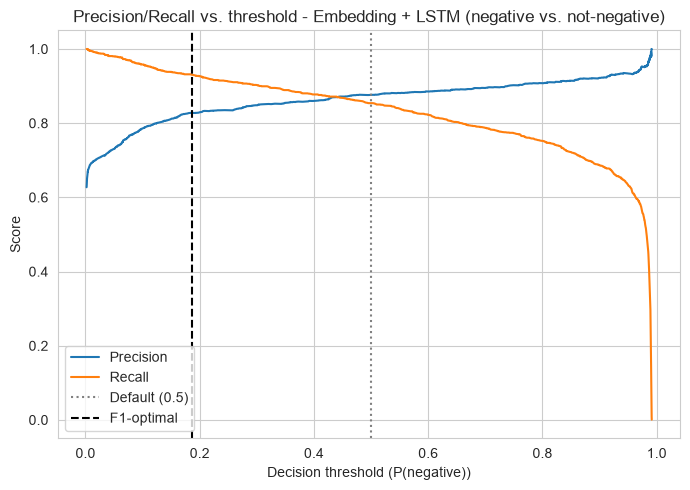

Precision at recall-priority threshold: 0.7979 (recall=0.9501)


In [23]:
model_test_probas = {
    "TF-IDF + Logistic Regression": baseline_proba_ordered,
    "Embedding + LSTM": lstm_test_proba,
    "Embedding + 1D CNN": cnn_test_proba,
}
best_model_name = results_table["Macro F1"].idxmax()
print(f"Best model by test macro-F1: {best_model_name}")

y_test_is_negative = (y_test == "negative").astype(int)
best_negative_proba = model_test_probas[best_model_name][:, class_order.index("negative")]

precisions, recalls, thresholds = precision_recall_curve(y_test_is_negative, best_negative_proba)
f1_scores = 2 * precisions * recalls / (precisions + recalls + 1e-12)
best_f1_idx = f1_scores[:-1].argmax()
f1_optimal_threshold = thresholds[best_f1_idx]

recall_priority_idx = np.where(recalls[:-1] >= 0.95)[0]
recall_priority_threshold = thresholds[recall_priority_idx[-1]] if len(recall_priority_idx) else thresholds[0]

print(f"F1-optimal threshold: {f1_optimal_threshold:.3f} (precision={precisions[best_f1_idx]:.4f}, recall={recalls[best_f1_idx]:.4f})")
print(f"Recall-priority threshold (>=95% recall on negative): {recall_priority_threshold:.3f}")

fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(thresholds, precisions[:-1], label="Precision")
ax.plot(thresholds, recalls[:-1], label="Recall")
ax.axvline(0.5, color="grey", linestyle=":", label="Default (0.5)")
ax.axvline(f1_optimal_threshold, color="black", linestyle="--", label="F1-optimal")
ax.set_xlabel("Decision threshold (P(negative))")
ax.set_ylabel("Score")
ax.set_title(f"Precision/Recall vs. threshold - {best_model_name} (negative vs. not-negative)")
ax.legend()
plt.tight_layout()
plt.show()

precision_at_recall_priority = precisions[:-1][recall_priority_idx[-1]] if len(recall_priority_idx) else precisions[0]
recall_at_recall_priority = recalls[:-1][recall_priority_idx[-1]] if len(recall_priority_idx) else recalls[0]
print(f"Precision at recall-priority threshold: {precision_at_recall_priority:.4f} (recall={recall_at_recall_priority:.4f})")


### 8.1 Results - Negative vs. not-negative triage threshold

The best model by test macro-F1 (section 7.1) is **Embedding + LSTM**, so it is the model reframed here as the binary "negative vs. not-negative" triage trigger.

| Threshold | Precision | Recall | Selection rule |
|---|---|---|---|
| 0.186 | 0.8279 | 0.9318 | F1-optimal |
| 0.119 | 0.7979 | 0.9501 | recall-priority (at least 95% recall on `negative`) |

Both recommended thresholds sit far below the naive 0.5 cutoff a 3-class `argmax` implicitly uses. At 0.186, the model catches 93.18% of genuinely negative tweets at 82.79% precision; pushed further to 0.119, recall rises to 95.01% at the cost of precision falling to 79.79%. For a triage queue where missing a genuine complaint is worse than an unnecessary review (the Head of CX framing from section 1), the recall-priority threshold (0.119) is the more defensible operating point of the two, and it is the one carried into the exposure analysis in section 8.2.

### 8.2 Exposure-weighted miss analysis

`retweet_count` is used here as a visibility/exposure proxy: a missed
negative tweet (false negative) that was heavily retweeted is a bigger
reputational risk than one nobody saw. This is a lighter-weight analogue of
project 03's monetary cost-benefit matrix: this dataset has no dollar
figure, but it does have a real reach signal.

In [24]:
# idx_test (kept alongside X_test/y_test since section 4.3) recovers the
# original rows behind the test split, to access retweet_count.
test_retweets = df.loc[idx_test, "retweet_count"].values

default_pred_negative = (best_negative_proba >= 0.5).astype(int)
recommended_pred_negative = (best_negative_proba >= recall_priority_threshold).astype(int)

fn_default = (y_test_is_negative == 1) & (default_pred_negative == 0)
fn_recommended = (y_test_is_negative == 1) & (recommended_pred_negative == 0)

print(f"False negatives at default threshold (0.5): {fn_default.sum()}")
print(f"  Retweet count among those misses - mean: {test_retweets[fn_default].mean():.3f}, max: {test_retweets[fn_default].max()}")
print(f"False negatives at recommended threshold ({recall_priority_threshold:.3f}): {fn_recommended.sum()}")
print(f"  Retweet count among those misses - mean: {test_retweets[fn_recommended].mean() if fn_recommended.sum() else 0:.3f}, "
      f"max: {test_retweets[fn_recommended].max() if fn_recommended.sum() else 0}")
print(f"\nRetweet count across all negative test tweets - mean: {test_retweets[y_test_is_negative == 1].mean():.3f}, "
      f"max: {test_retweets[y_test_is_negative == 1].max()}")

flagged_default = int(default_pred_negative.sum())
flagged_recommended = int(recommended_pred_negative.sum())
print()
print(f"Tweets flagged as 'negative' (sent to the triage queue) at default threshold (0.5): {flagged_default} of {len(y_test_is_negative)} ({flagged_default/len(y_test_is_negative):.2%})")

print(f"Tweets flagged as 'negative' at recommended threshold ({recall_priority_threshold:.3f}): {flagged_recommended} of {len(y_test_is_negative)} ({flagged_recommended/len(y_test_is_negative):.2%})")


False negatives at default threshold (0.5): 199
  Retweet count among those misses - mean: 0.040, max: 2
False negatives at recommended threshold (0.119): 68
  Retweet count among those misses - mean: 0.059, max: 2

Retweet count across all negative test tweets - mean: 0.092, max: 32

Tweets flagged as 'negative' (sent to the triage queue) at default threshold (0.5): 1328 of 2173 (61.11%)
Tweets flagged as 'negative' at recommended threshold (0.119): 1623 of 2173 (74.69%)


### 8.2 Results - Exposure-weighted miss analysis

| Threshold | False negatives | Retweets among misses (mean / max) | Tweets flagged as negative |
|---|---|---|---|
| 0.500 (default) | 199 | 0.040 / 2 | 1,328 of 2,173 (61.11%) |
| 0.119 (recommended) | 68 | 0.059 / 2 | 1,623 of 2,173 (74.69%) |
| *(all negative test tweets)* | 1,363 | 0.092 / 32 | |

Lowering the threshold from 0.5 to 0.119 cuts missed negative tweets by **65.8%** (199 to 68, a reduction of 131 tweets), at the cost of routing **13.6 additional percentage points** of test tweets to the triage queue (61.11% to 74.69%). The exposure story is less dramatic than it could have been: the maximum retweet count among the missed tweets stays at **2** under both thresholds, far below the **32** retweets seen on the most-retweeted negative tweet in the test set, so even the default threshold was not disproportionately missing the highest-visibility complaints. `retweet_count` itself is a weak signal in this dataset overall (mean 0.092 across all negative test tweets; most tweets get zero retweets), so this check is best read as a directional reassurance (no evidence the model is blind to viral complaints) rather than as a strong driver of the threshold recommendation.

## 9. Interpretability

### 9.1 TF-IDF + Logistic Regression - top coefficients per class

Logistic Regression assigns one coefficient per word per class: a positive
coefficient pushes the prediction toward that class, a negative one pushes
away from it. The code below extracts the strongest words in each direction
for every class, the most direct form of interpretability available in this
notebook (see the section 6.0 framework's note on why the neural models
cannot be read this literally).

In [25]:
tfidf_vectorizer = baseline_model.named_steps["tfidf"]
logreg = baseline_model.named_steps["clf"]
feature_names = np.array(tfidf_vectorizer.get_feature_names_out())

top_n = 12
coef_tables = {}
for class_idx, class_label in enumerate(logreg.classes_):
    coefs = logreg.coef_[class_idx]
    top_positive_idx = np.argsort(coefs)[-top_n:][::-1]
    top_negative_idx = np.argsort(coefs)[:top_n]
    coef_tables[class_label] = pd.DataFrame({
        "Top words pushing TOWARD this class": feature_names[top_positive_idx],
        "Coefficient (+)": coefs[top_positive_idx].round(3),
        "Top words pushing AWAY from this class": feature_names[top_negative_idx],
        "Coefficient (-)": coefs[top_negative_idx].round(3),
    })

for class_label in class_order:
    print(f"--- {class_label} ---")
    print(coef_tables[class_label].to_string(index=False))
    print()


--- negative ---
Top words pushing TOWARD this class  Coefficient (+) Top words pushing AWAY from this class  Coefficient (-)
                                not            3.537                                  thank           -4.213
                              hours            3.334                                 thanks           -4.141
                               hold            3.281                                   love           -2.386
                              worst            3.031                                  great           -2.065
                                 no            2.876                                awesome           -1.990
                               hour            2.861                                amazing           -1.756
                                hrs            2.655                                   best           -1.704
                            nothing            2.570                                   good           -1.511
  

### 9.1 Results - TF-IDF + Logistic Regression coefficients

| Class | Top words pushing TOWARD it | Top words pushing AWAY from it |
|---|---|---|
| negative | not, hours, hold, worst, no, hour, hrs, nothing, delayed, bag, luggage, cancelled | thank, thanks, love, great, awesome, amazing, best, good, thx, kudos, worries |
| neutral | hi, chance, dm, carry, march, tomorrow, possible, vegas, policy | great, airline, awesome, helpful, best, customer, lost, appreciate, wait, staff, hour |
| positive | thanks, great, awesome, thank, best, love, amazing, thx, appreciate, kudos, excellent, wonderful | not, need, hold, hours, no, worst, told, delayed, policy, feedback, nothing, online |

Three findings stand out. First, the `negative` class's strongest word is the negation `not` (coefficient +3.537), direct evidence that keeping negation words out of the stopword list (section 4.1) was the right call: had `not` been removed, this single strongest signal in the whole model would have been discarded. Second, `hours`/`hour`/`hrs` all push toward `negative` with large coefficients (+3.334, +2.861, +2.655), matching "Late Flight" being the second most common negative reason in section 3.2 (1,650 tweets). Third, the `neutral` class's top words ("hi", "dm", "chance", "possible") read as customer-service-inquiry language, tweets asking a question or requesting a DM, rather than clearly polarized language, consistent with H2's finding that `neutral` is intrinsically ambiguous rather than simply small.

### 9.2 Embedding nearest neighbors

A qualitative check that the LSTM's learned embedding space captured
sentiment structure, following Chollet's ch. 6.1.2 discussion of geometric
relationships between word vectors: do the nearest neighbors of a handful of
sentiment-loaded words make intuitive sense?

In [26]:
embedding_weights = lstm_model.layers[0].get_weights()[0]
word_index = tokenizer.word_index

def nearest_neighbors(word, k=6):
    idx = word_index.get(word)
    if idx is None or idx >= embedding_weights.shape[0]:
        return None
    target_vector = embedding_weights[idx].reshape(1, -1)
    similarities = cosine_similarity(target_vector, embedding_weights)[0]
    nearest_idx = similarities.argsort()[::-1]
    index_to_word = {v: k_ for k_, v in word_index.items()}
    neighbors = []
    for i in nearest_idx:
        if i == idx or i == 0:
            continue
        w = index_to_word.get(i)
        if w is not None:
            neighbors.append((w, round(float(similarities[i]), 3)))
        if len(neighbors) == k:
            break
    return neighbors

for probe_word in ["delay", "thanks", "rude", "love", "cancelled"]:
    neighbors = nearest_neighbors(probe_word)
    print(f"{probe_word!r} -> {neighbors}")


'delay' -> [('hire', 0.932), ('nightmare', 0.932), ('rude', 0.929), ('worst', 0.929), ('anyone', 0.928), ('useless', 0.925)]
'thanks' -> [('awesome', 0.923), ('great', 0.914), ('excellent', 0.91), ('thank', 0.905), ('enjoy', 0.901), ('kudos', 0.9)]
'rude' -> [('worst', 0.964), ('unacceptable', 0.957), ('paid', 0.955), ('ridiculous', 0.952), ('disappointed', 0.949), ('poor', 0.948)]
'love' -> [('thank', 0.926), ('best', 0.925), ('awesome', 0.923), ('excellent', 0.908), ('thanks', 0.89), ('worries', 0.888)]
'cancelled' -> [('hold', 0.819), ('worst', 0.811), ('being', 0.81), ('rude', 0.805), ('forgetting', 0.8), ("hasn't", 0.8)]


### 9.2 Results - Embedding nearest neighbors

| Probe word | Nearest neighbors (cosine similarity) |
|---|---|
| delay | hire (0.932), nightmare (0.932), rude (0.929), worst (0.929), anyone (0.928), useless (0.925) |
| thanks | awesome (0.923), great (0.914), excellent (0.910), thank (0.905), enjoy (0.901), kudos (0.900) |
| rude | worst (0.964), unacceptable (0.957), paid (0.955), ridiculous (0.952), disappointed (0.949), poor (0.948) |
| love | thank (0.926), best (0.925), awesome (0.923), excellent (0.908), thanks (0.890), worries (0.888) |
| cancelled | hold (0.819), worst (0.811), being (0.810), rude (0.805), forgetting (0.800), hasn't (0.800) |

Four of the five probe words have neighbors that clearly share their polarity: "delay" clusters with "nightmare"/"rude"/"worst"/"useless" (all negative-toned, similarities 0.925 to 0.932); "thanks" clusters with "awesome"/"great"/"excellent"/"kudos" (all positive-toned, 0.900 to 0.923); "rude" clusters even more tightly with "unacceptable"/"ridiculous"/"disappointed"/"poor" (0.948 to 0.964, the highest similarities of any probe word here); and "cancelled" clusters with "hold"/"worst"/"rude" (negative-toned, 0.805 to 0.819). "love"'s neighbor list is the one exception worth flagging honestly: "worries" (0.888) does not obviously share love's positive charge on its own, most likely because it usually appears in the negated phrase "no worries", which is positive in context but would look neutral-to-negative to an embedding that does not model word order. This is exactly the interpretability gap called out in the section 6.0 framework: the embedding captured something about sentiment structure well enough for 4 of 5 probes, but reading it is inherently more approximate than reading the LogReg coefficients in section 9.1.

## 10. Business Storytelling & Key Findings

### 10.1 Hypotheses & Results

| # | Hypothesis | Result |
|---|---|---|
| H1 | Embedding + LSTM / 1D CNN outperform the TF-IDF + Logistic Regression baseline on macro-F1 | **Confirmed.** On the held-out test set, TF-IDF + Logistic Regression scored macro-F1 0.7101. Embedding + LSTM reached 0.7326 (+3.2% relative) and Embedding + 1D CNN reached 0.7212 (+1.6% relative). Both neural models beat the baseline on every headline metric (accuracy, macro-F1, weighted-F1), and the LSTM was the strongest model overall. |
| H2 | Accuracy overstates performance on the minority classes given the negative-class imbalance | **Partially confirmed.** Accuracy exceeded macro-F1 by about 5 to 6 points for every model (baseline 0.7607 vs. 0.7101, LSTM 0.7911 vs. 0.7326, CNN 0.7713 vs. 0.7212), confirming the core claim. However, the class that struggled most was not `positive` (16.1% of tweets) as hypothesized, but `neutral` (21.2%): every model's `neutral` recall (0.639 to 0.665) trailed its `negative` recall (0.809 to 0.870), while `positive` recall (0.674 to 0.749) was often close to, or even above, `negative` recall for the CNN. Class size alone did not predict difficulty; `neutral` tweets appear to be intrinsically more ambiguous than genuinely rare. |
| H3 | The 1D CNN trains faster than the LSTM at comparable classification performance | **Confirmed.** The CNN trained 2.21x faster per epoch (3.83s vs. 8.46s) and converged in fewer epochs (5 vs. 6), while reaching 98.4% of the LSTM's test macro-F1 (0.7212 vs. 0.7326), a small, honest performance gap in exchange for a large speed advantage. |


### 10.2 Key Findings

- **Deep learning beat the classic baseline, but by a modest margin.** Embedding + LSTM's test macro-F1 of 0.7326 is only 3.2% better (relative) than TF-IDF + Logistic Regression's 0.7101, evidence that for short, informal tweets a well-regularized bag-of-words model with bigrams remains a strong baseline, not a strawman.
- **`neutral` tweets, not `positive` ones, are the hardest to classify.** Every model's recall on `neutral` (0.639 to 0.665) was its weakest class, even though `positive` is the smaller class (16.1% vs. 21.2%). Semantic ambiguity, not just sample size, appears to drive the difficulty.
- **The 1D CNN is the pragmatic production choice for this task.** It trains 2.21x faster per epoch than the LSTM (3.83s vs. 8.46s) and lands within 1.5 macro-F1 points of it (0.7212 vs. 0.7326), while narrowly winning on ranking ability (macro ROC-AUC 0.8923 vs. 0.8868).
- **Calibrating the decision threshold changes the triage outcome more than the model choice does.** Lowering the negative-vs-not-negative threshold from 0.5 to 0.119 (chosen for at least 95% recall on `negative`) cuts missed negative tweets from 199 to 68 (a 65.8% reduction), at the cost of routing 74.69% of test tweets to the triage queue instead of 61.11%.
- **The LSTM's learned embedding organized itself around real sentiment structure**, with no explicit word-level supervision: nearest neighbors of "rude" were "worst", "unacceptable" and "ridiculous"; neighbors of "thanks" were "awesome", "great" and "excellent" (section 9.2).
- **The TF-IDF baseline's top negative-class coefficients** ("not", "hours", "hold", "worst", "delayed", "cancelled") map directly onto the top negative reasons found in the EDA ("Customer Service Issue": 2,885 tweets, "Late Flight": 1,650), showing the linear baseline picks up on the same operational pain points a human analyst would flag.


## 11. Conclusions & Next Steps

This notebook set out to answer whether tweet sentiment can be classified accurately enough to support a live triage queue, and whether learned embeddings beat a classic bag-of-words baseline for that task. The answer to both is yes, with real nuance attached. Embedding + LSTM is the strongest model tested (test macro-F1 0.7326, accuracy 0.7911), improving on the TF-IDF + Logistic Regression baseline (macro-F1 0.7101) by a modest but consistent margin across every headline metric. For a deployment that prioritizes training and inference cost, Embedding + 1D CNN is a credible alternative: it trains 2.21x faster per epoch and gives up only 1.5 macro-F1 points relative to the LSTM.

For the Head of CX persona, the most actionable result is not the model choice itself but the threshold calibration in section 8: recalibrating the negative-vs-not-negative decision threshold from the default 0.5 to 0.119 cuts missed negative tweets by 65.8% (199 to 68 on the test set), at the cost of a larger triage queue (61.11% to 74.69% of tweets). That threshold decision, not the choice between LSTM and CNN, is the highest-leverage lever found in this analysis, echoing project 03's finding that decision thresholds often matter more than model selection.

**Planned next steps, regardless of the final numbers above:**
- **Pretrained word embeddings (GloVe) via transfer learning**, per Chollet ch. 6.1.2/6.1.3 and the *Hands-On NLP with Python* ch. 5 example. This is likely to help most if the training set were smaller; worth testing here as a direct A/B against the from-scratch embeddings used in this notebook.
- **Bidirectional and/or stacked LSTM layers** (Chollet ch. 6.3.7-6.3.8) to test whether reading the tweet in both directions or adding depth improves on the single-layer LSTM used here.
- **Attention-based architectures** (per the *Hands-On NLP with Python* ch. 5 discussion of attention networks for document classification), which could also double as a more granular interpretability tool than the nearest-neighbor check in section 9.2.
- **Systematic hyperparameter search** (embedding dimension, LSTM/Conv1D units, learning rate) via `KerasTuner`, instead of the fixed architecture choices made here to keep training time predictable.
- **Oversampling (e.g. SMOTE on TF-IDF features, or text augmentation for the neural pipeline) as an alternative to `class_weight`** for handling the class imbalance, compared head-to-head against the approach used in this notebook.
- **A sensitivity check on the label noise identified in section 2.3** (tweets with identical text but inconsistent crowd labels), e.g. resolving them to a majority label or excluding them, to see whether that measurably changes the metrics in section 7.
- **A dedicated look at why `neutral` is the hardest class** (per H2), since it was not the outcome originally hypothesized; likely candidates include genuinely mixed-sentiment tweets and crowd-labeling inconsistency at the `neutral` boundary.